## 🌐 **Google Drive Connection**

In [1]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\Drive/Thereluctants/Second Challenge"
%cd $current_dir

Mounted at /gdrive
/gdrive/MyDrive/Thereluctants/Second Challenge


## ⚙️ **Libraries Import**

In [2]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.9.0+cu126
Device: cuda


**DATA LOADING**

In [8]:
def load_images_from_folder(folder):
    labels_df = pd.read_csv(os.path.join(os.getcwd(), "train_labels.csv"))
    labels = []
    images = []

    for filename in os.listdir(folder):

        # Skip masks
        if filename.startswith("mask_"):
            continue

        print(f"Loading {filename}")

        # ---- Load image ----
        img = cv2.imread(os.path.join(folder, filename))
        if img is None:
            continue

        # BGR -> RGB
        img = img[..., ::-1].astype(np.float32) / 255.0

        # ---- Load matching mask ----
        mask_name = "mask_" + filename.split("_")[1]
        mask = cv2.imread(os.path.join(folder, mask_name), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            continue

        # ---- Convert mask to binary ----
        mask = (mask > 0).astype(np.uint8)

        # ---- APPLY ROI MASK ----
        roi = img * mask[..., None]

        # ---- Resize with padding to 224x224 ----
        h, w = roi.shape[:2]
        scale = 224 / max(h, w)
        new_h, new_w = int(h * scale), int(w * scale)
        roi_resized = cv2.resize(roi, (new_w, new_h))

        # Compute padding
        top = (224 - new_h) // 2
        bottom = 224 - new_h - top
        left = (224 - new_w) // 2
        right = 224 - new_w - left

        # Pad with black
        roi_padded = cv2.copyMakeBorder(
            roi_resized, top, bottom, left, right,
            cv2.BORDER_CONSTANT, value=0
        )

        # Get class label (only after success)
        label = labels_df.loc[
            labels_df['sample_index'] == filename, 'label'
        ].values[0]

        images.append(roi_padded)
        labels.append(label)

    return np.array(images), labels

# Usage
img_path = 'train_data_updated'
images, labels = load_images_from_folder(img_path)
print(f"Loaded {len(images)} images")
print(f"Loaded {len(labels)} labels")

Loading img_0354.png
Loading img_0330.png
Loading img_0327.png
Loading img_0324.png
Loading img_0341.png
Loading img_0294.png
Loading img_0358.png
Loading img_0337.png
Loading img_0336.png
Loading img_0298.png
Loading img_0307.png
Loading img_0325.png
Loading img_0363.png
Loading img_0334.png
Loading img_0349.png
Loading img_0284.png
Loading img_0292.png
Loading img_0320.png
Loading img_0300.png
Loading img_0306.png
Loading img_0308.png
Loading img_0350.png
Loading img_0288.png
Loading img_0321.png
Loading img_0339.png
Loading img_0343.png
Loading img_0340.png
Loading img_0279.png
Loading img_0305.png
Loading img_0281.png
Loading img_0297.png
Loading img_0348.png
Loading img_0364.png
Loading img_0326.png
Loading img_0360.png
Loading img_0352.png
Loading img_0338.png
Loading img_0356.png
Loading img_0290.png
Loading img_0437.png
Loading img_0428.png
Loading img_0367.png
Loading img_0396.png
Loading img_0429.png
Loading img_0381.png
Loading img_0387.png
Loading img_0446.png
Loading img_0

**Show some images**

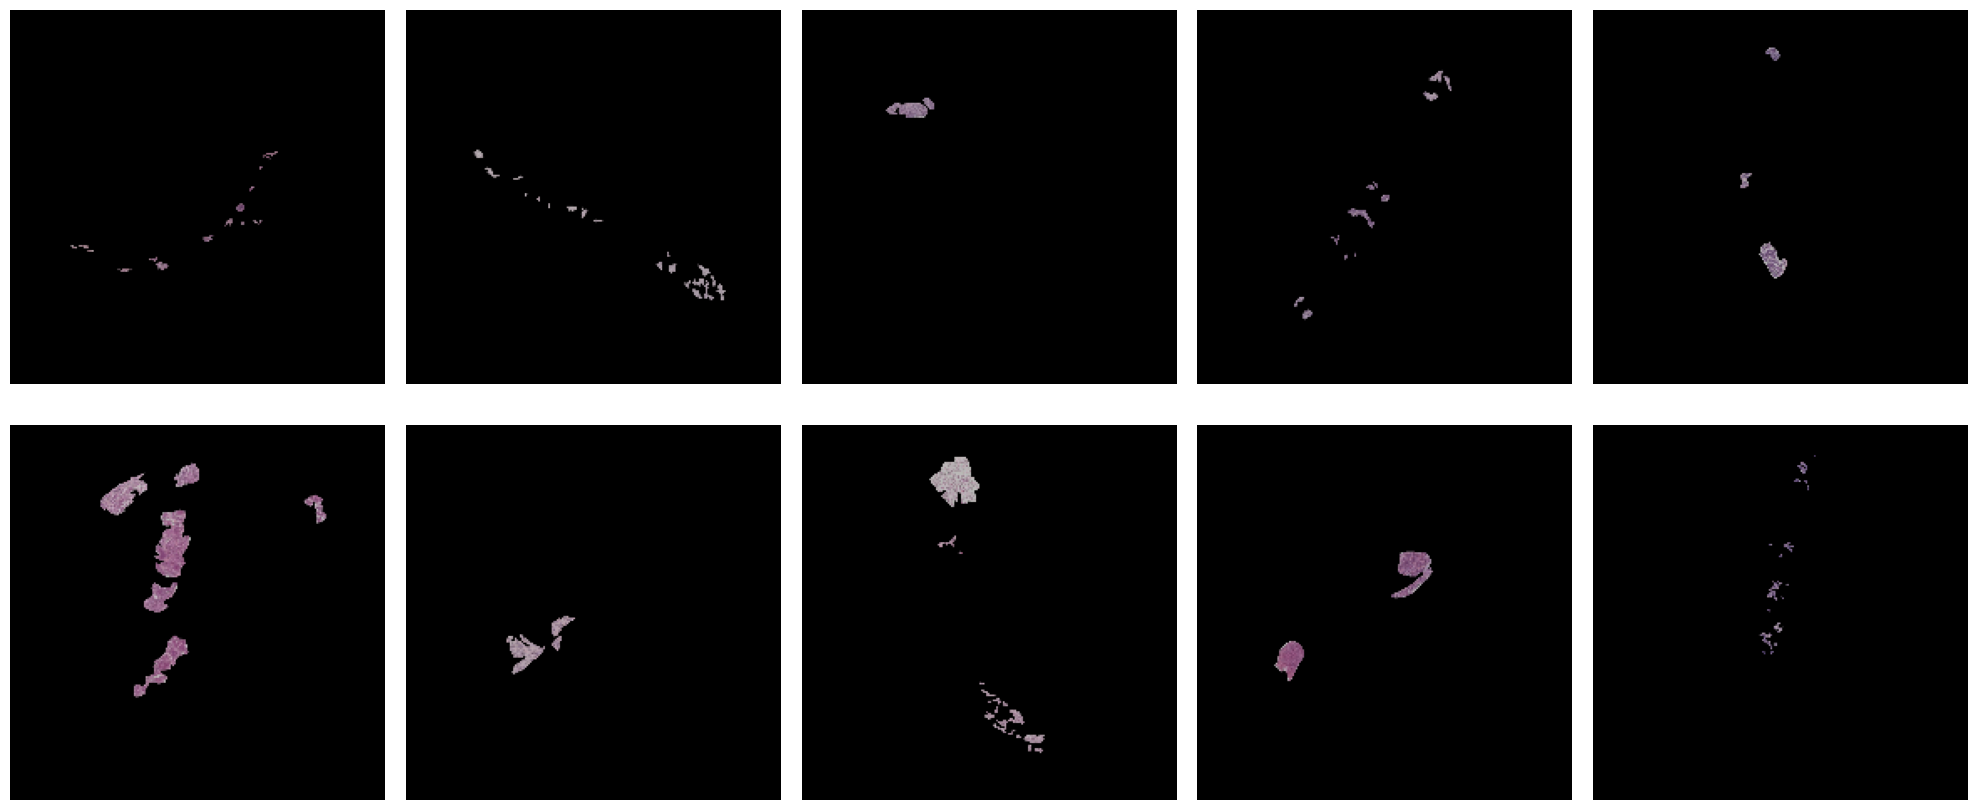

In [9]:
# Number of images to display
num_img = 10
# Create subplots for displaying images
fig, axes = plt.subplots(2, num_img//2, figsize=(20, 9))
for i in range(num_img):
    ax = axes[i%2, i%num_img//2]
    ax.imshow(np.clip(images[i], 0, 1))
    ax.axis('off')
plt.tight_layout()
plt.show()

**DATA PREPROCESSING**

In [10]:
label_mapping = {
    'Luminal B': 0,
    'Luminal A': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}

# Convert string labels to numerical labels
numerical_labels = [label_mapping[label] for label in labels]

print(f"Original labels (first 5): {labels[:5]}")
print(f"Numerical labels (first 5): {numerical_labels[:5]}")
print(f"Number of numerical labels: {len(numerical_labels)}")


Original labels (first 5): ['Luminal A', 'Luminal B', 'Luminal A', 'Luminal B', 'Triple negative']
Numerical labels (first 5): [1, 0, 1, 0, 3]
Number of numerical labels: 581


**Data Exploration**

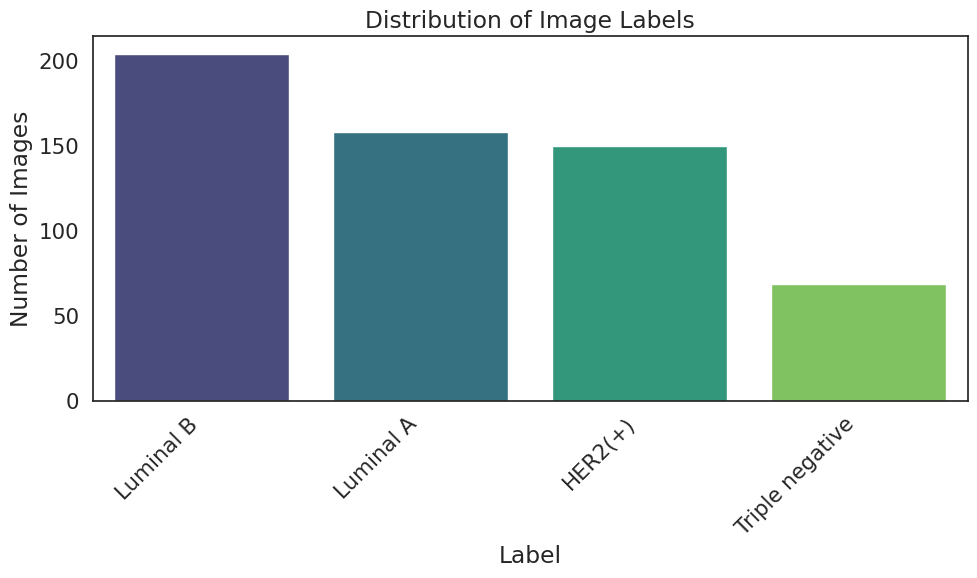

Label distribution:
Luminal B          204
Luminal A          158
HER2(+)            150
Triple negative     69
Name: count, dtype: int64


In [11]:
# Get the counts of each label
label_counts = pd.Series(numerical_labels).value_counts().sort_index()

# Map numerical labels to their original names for better readability in the plot
label_names = {v: k for k, v in label_mapping.items()}
mapped_counts = label_counts.rename(index=label_names)

# Create a bar plot (histogram)
plt.figure(figsize=(10, 6))
sns.barplot(x=mapped_counts.index, y=mapped_counts.values, palette='viridis')
plt.title('Distribution of Image Labels')
plt.xlabel('Label')
plt.ylabel('Number of Images')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Label distribution:")
print(mapped_counts)


**Showing some images for different labels**

In [12]:
def show_n_images_for_label(images, labels_list, label_name, n=5):
    """
    Displays the first n images of a specific label.

    Args:
        images (np.ndarray): Array of image data.
        labels_list (list): List of numerical labels corresponding to the images.
        label_name (str): The name of the label to display (e.g., 'Luminal B').
        n (int): The number of images to display for the given label.
    """
    # Map the label name back to its numerical representation
    try:
        numerical_label = label_mapping[label_name]
    except KeyError:
        print(f"Error: Label '{label_name}' not found in label_mapping.")
        return

    # Filter images and labels for the specified numerical_label
    filtered_images = []
    filtered_labels = []
    for i, label in enumerate(labels_list):
        if label == numerical_label:
            filtered_images.append(images[i])
            filtered_labels.append(label)

    if not filtered_images:
        print(f"No images found for label: {label_name}")
        return

    # Determine how many images to show (min of n or available images)
    num_to_show = min(n, len(filtered_images))

    # Create subplots
    fig, axes = plt.subplots(1, num_to_show, figsize=(4 * num_to_show, 4))
    fig.suptitle(f"First {num_to_show} images for label: {label_name}", fontsize=16)

    # Handle case with single image
    if num_to_show == 1:
        axes = [axes]

    for i in range(num_to_show):
        ax = axes[i]
        ax.imshow(np.clip(filtered_images[i], 0, 1))
        ax.set_title(f"Label: {label_name}")
        ax.axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
    plt.show()


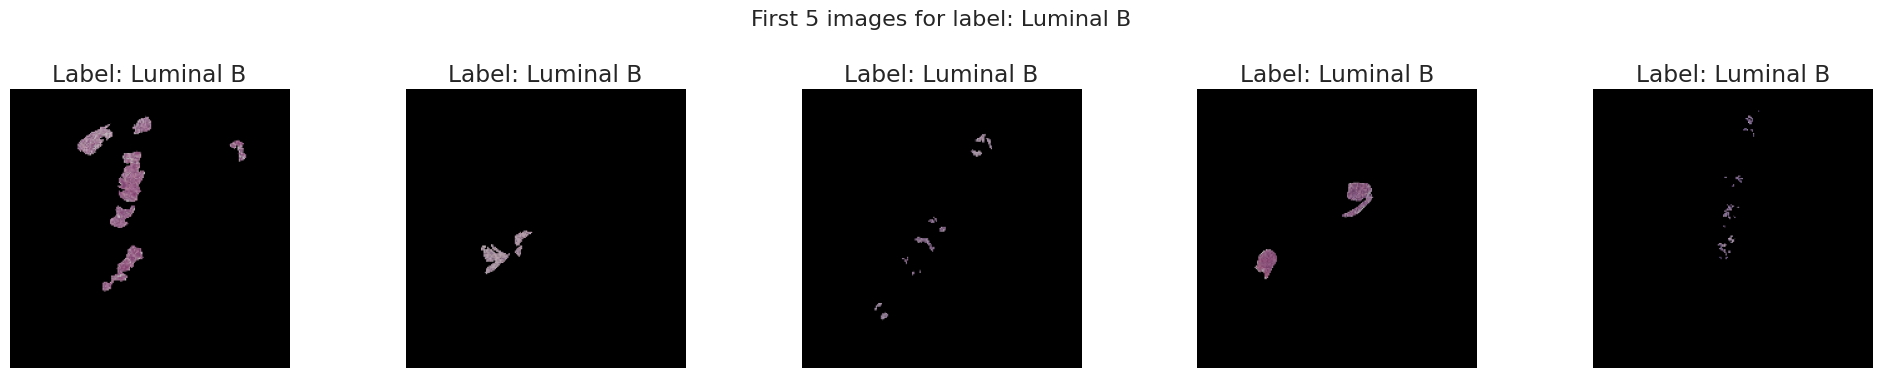

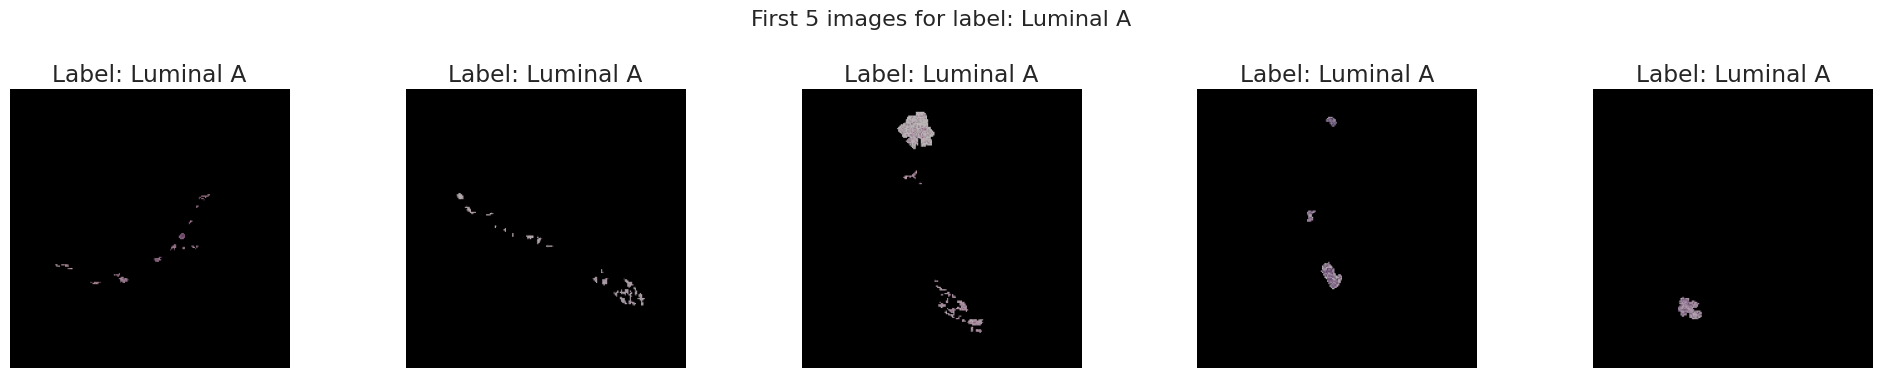

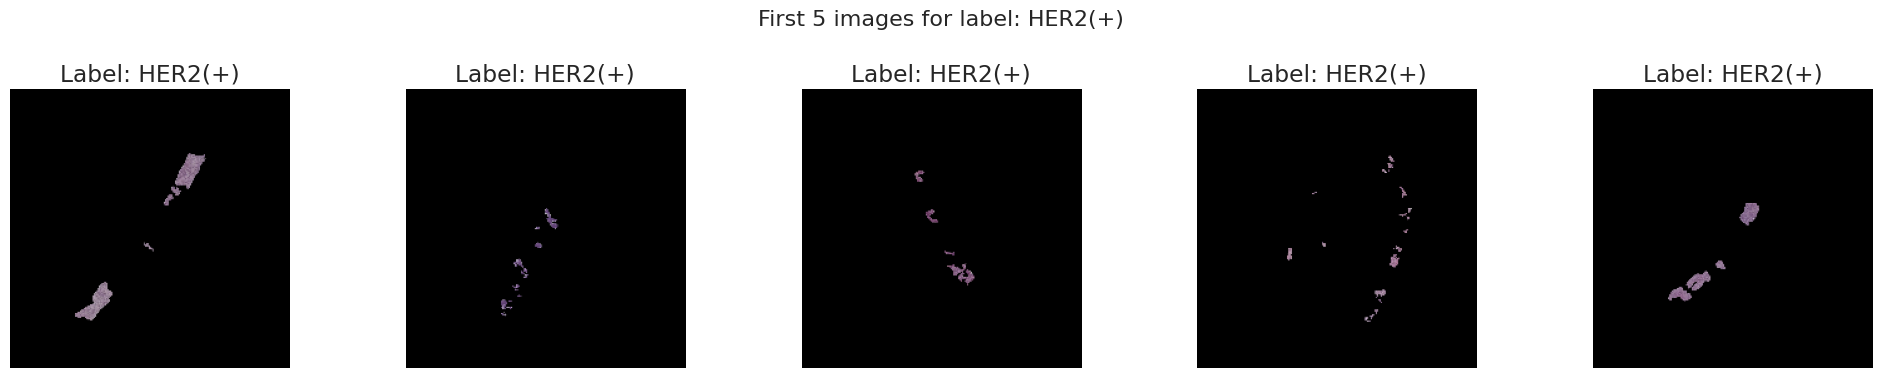

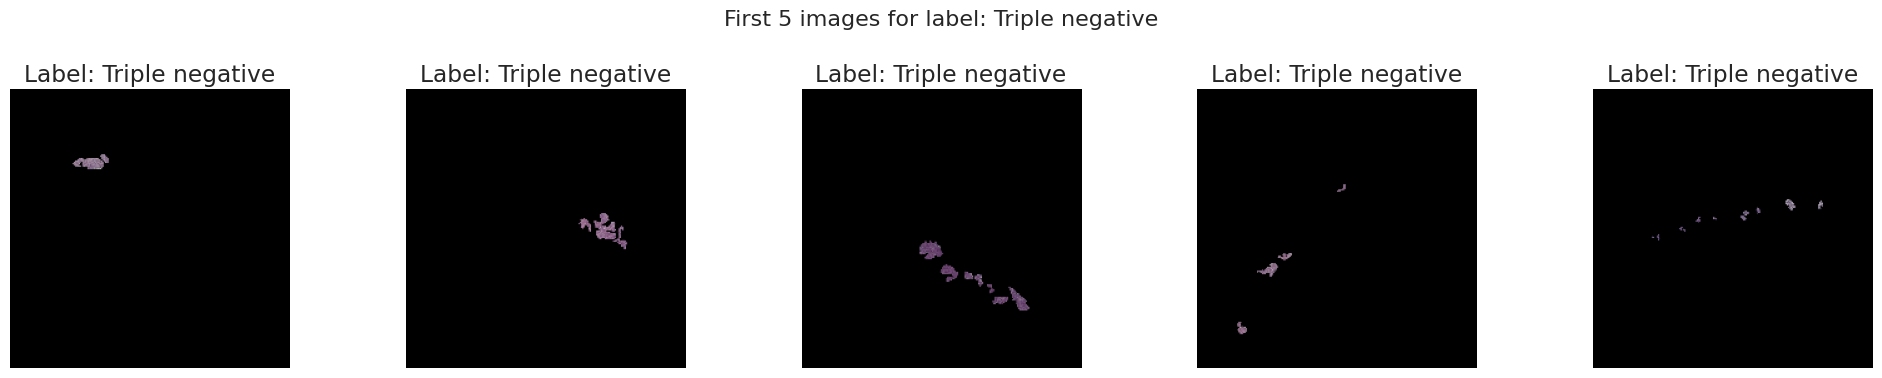

In [13]:
show_n_images_for_label(images, numerical_labels, 'Luminal B', 5)
show_n_images_for_label(images, numerical_labels, 'Luminal A', 5)
show_n_images_for_label(images, numerical_labels, 'HER2(+)', 5)
show_n_images_for_label(images, numerical_labels, 'Triple negative', 5)

**VALIDATION AND TEST SPLITTING**

In [14]:
# Split data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    images, numerical_labels, test_size=0.1, random_state=SEED, stratify=numerical_labels
)
input_shape = (X_train.shape[3], X_train.shape[1], X_train.shape[2])

print(f"Training images shape: {X_train.shape}")
print(f"Validation images shape: {X_val.shape}")
print(f"Training labels length: {len(y_train)}")
print(f"Validation labels length: {len(y_val)}")

Training images shape: (522, 224, 224, 3)
Validation images shape: (59, 224, 224, 3)
Training labels length: 522
Validation labels length: 59


## **Image Augmentation**

In [15]:
# Define image transformations for training and validation
IMG_SIZE = 224 # Assuming images are 224x224, adjust if needed

# Apply transformations to the datasets
class CustomTensorDataset(TensorDataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[idx] # Images are already numpy arrays in HWC format
        label = self.labels[idx]

        # Convert numpy array to PIL Image for torchvision transforms
        image = Image.fromarray((image * 255).astype(np.uint8))

        if self.transform:
            # Apply the transformation pipeline, which includes converting to tensor
            image = self.transform(image)
        else:
            # If no transform specified, convert to tensor manually (e.g. for val_dataset without custom transforms)
            image = transforms.ToTensor()(image)

        return image, torch.tensor(label,dtype=torch.long)

### **Auto-Augmentation**

Auto-augmentation automatically searches for optimal data augmentation policies to improve model performance. This often leads to better generalization and accuracy compared to hand-crafted augmentation techniques.

In [16]:
from torchvision.transforms.v2 import AutoAugment, AutoAugmentPolicy

# Define image transformations for training and validation
IMG_SIZE = 224 # Assuming images are 224x224, adjust if needed

train_transform = transforms.Compose([
    transforms.ToImage(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=0),
    AutoAugment(policy=AutoAugmentPolicy.IMAGENET), # Add AutoAugment here
    transforms.ToDtype(torch.float32, scale=True), # Explicitly convert to float32 and scale to [0.0, 1.0]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.ToImage(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToDtype(torch.float32, scale=True), # Explicitly convert to float32 and scale to [0.0, 1.0]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Apply transformations to the datasets
# The CustomTensorDataset class is already defined, so no need to redefine it.

# Create datasets with transformations
train_dataset_transformed = CustomTensorDataset(X_train, y_train, transform=train_transform)
val_dataset_transformed = CustomTensorDataset(X_val, y_val, transform=val_transform)

print(f"Training dataset size with augmentations: {len(train_dataset_transformed)}")
print(f"Validation dataset size with transformations: {len(val_dataset_transformed)}")

Training dataset size with augmentations: 522
Validation dataset size with transformations: 59


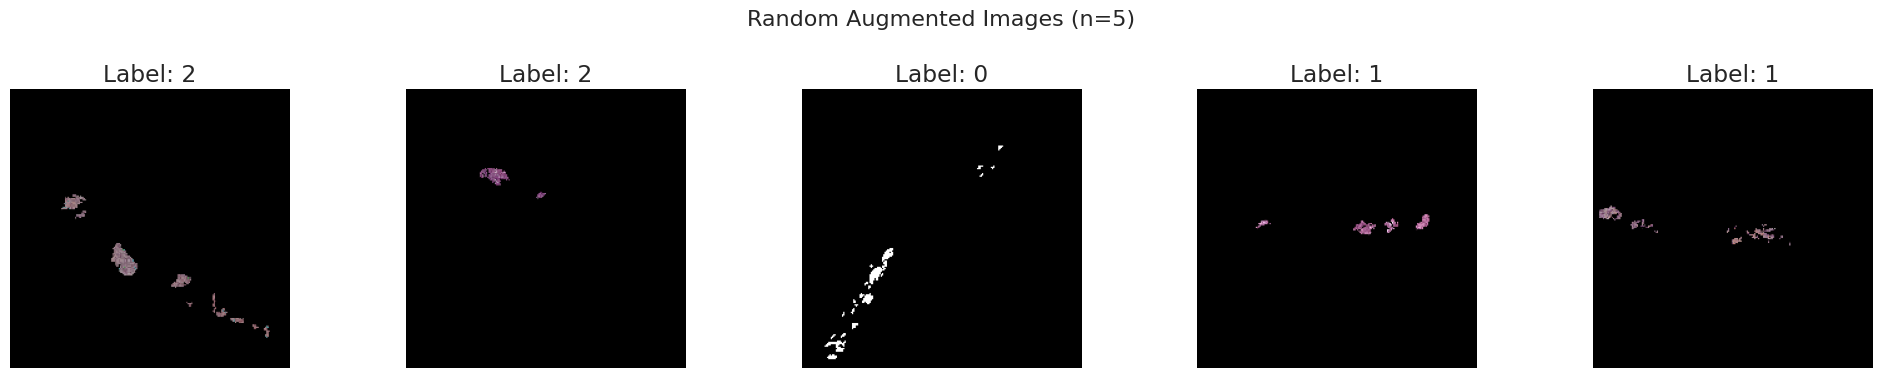

In [17]:
def show_random_augmented_images(dataset, n=5):
    """
    Displays n random augmented images from a dataset.
    """
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    fig.suptitle(f"Random Augmented Images (n={n})", fontsize=16)

    for i in range(n):
        # Get a random index
        random_idx = random.randint(0, len(dataset) - 1)
        image, label = dataset[random_idx]

        # Unnormalize image for display
        # StandardImageNet values, reverse operation of: transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        unnormalized_image = image * std + mean

        ax = axes[i]
        # Convert from C, H, W to H, W, C for matplotlib
        ax.imshow(unnormalized_image.permute(1, 2, 0).cpu().numpy().clip(0, 1))
        ax.set_title(f"Label: {label.item()}")
        ax.axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Show 5 random augmented images
show_random_augmented_images(train_dataset_transformed, n=5)

**CREATE DATALOADER**


In [18]:
def make_loader(ds, batch_size, shuffle, drop_last):
    """
    Create a PyTorch DataLoader with optimized settings.

    Args:
        ds (Dataset): PyTorch Dataset object
        batch_size (int): Number of samples per batch
        shuffle (bool): Whether to shuffle data at each epoch
        drop_last (bool): Whether to drop last incomplete batch

    Returns:
        DataLoader: Configured DataLoader instance
    """
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

batch_size = 32

train_loader = make_loader(train_dataset_transformed, batch_size, shuffle=True, drop_last=True)
val_loader = make_loader(val_dataset_transformed,batch_size=batch_size,shuffle=True,drop_last=True)



**BUILD THE MODEL**

In [19]:
import torch
import torch.nn as nn

class SimpleCNN_BN(nn.Module):
    """
    Simple CNN with Batch Normalization and an extra conv layer in the last block.
    """
    def __init__(self, input_shape=(3, 512, 512), num_classes=4, dropout_rate=0.2):
        super().__init__()

        # First convolutional block: 16 filters
        self.conv0 = nn.Conv2d(input_shape[0], 16, kernel_size=3, padding='same')
        self.bn0 = nn.BatchNorm2d(16)
        self.relu0 = nn.ReLU()
        self.mp0 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Second convolutional block: 32 filters
        self.conv1 = nn.Conv2d(16, 32, kernel_size=3, padding='same')
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.mp1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Third convolutional block: 64 filters
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding='same')
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.mp2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fourth convolutional block: 128 filters + extra conv
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding='same')
        self.bn3 = nn.BatchNorm2d(128)
        self.relu3 = nn.ReLU()

        # Compute flattened size dynamically
        with torch.no_grad():
            dummy_input = torch.zeros(1, *input_shape)
            dummy_output = self._forward_features(dummy_input)
            flattened_size = dummy_output.view(1, -1).shape[1]

        # Classification head
        self.classifier_head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout_rate),
            nn.Linear(flattened_size, num_classes)
        )

    def _forward_features(self, x):
        """Forward pass through conv layers."""
        # Block 1
        x = self.relu0(self.bn0(self.conv0(x)))
        x = self.mp0(x)

        # Block 2
        x = self.relu1(self.bn1(self.conv1(x)))
        x = self.mp1(x)

        # Block 3
        x = self.relu2(self.bn2(self.conv2(x)))
        x = self.mp2(x)

        # Block 4
        x = self.relu3(self.bn3(self.conv3(x)))
        return x

    def forward(self, x):
        """Forward pass through the whole network."""
        x = self._forward_features(x)
        x = self.classifier_head(x)
        return x


**TRAIN ONE EPOCH**

In [20]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [21]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm

        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

**VALIDATE ONE EPOCH**

In [22]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [23]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

**FIT**

In [24]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

**CREATE THE MODEL**

In [25]:
#PARAMETERS
LEARNING_RATE = 1e-3
EPOCHS = 500
PATIENCE = 60

# Regularisation
DROPOUT_RATE = 0.2         # Dropout probability
L1_LAMBDA = 0              # L1 penalty
L2_LAMBDA = 5e-4            # L2 penalty

# Set up loss function
criterion = nn.CrossEntropyLoss()


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 224, 224]             448
       BatchNorm2d-2         [-1, 16, 224, 224]              32
              ReLU-3         [-1, 16, 224, 224]               0
         MaxPool2d-4         [-1, 16, 112, 112]               0
            Conv2d-5         [-1, 32, 112, 112]           4,640
       BatchNorm2d-6         [-1, 32, 112, 112]              64
              ReLU-7         [-1, 32, 112, 112]               0
         MaxPool2d-8           [-1, 32, 56, 56]               0
            Conv2d-9           [-1, 64, 56, 56]          18,496
      BatchNorm2d-10           [-1, 64, 56, 56]             128
             ReLU-11           [-1, 64, 56, 56]               0
        MaxPool2d-12           [-1, 64, 28, 28]               0
           Conv2d-13          [-1, 128, 28, 28]          73,856
      BatchNorm2d-14          [-1, 128,

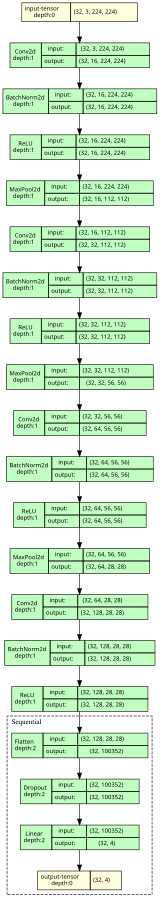

In [26]:
# Instantiate CNN model and move to computing device (CPU/GPU)
vanilla_model = SimpleCNN_BN(
    input_shape,
    4,
    dropout_rate=DROPOUT_RATE
).to(device)

# Display model architecture summary
summary(vanilla_model, input_size=input_shape)
model_graph = draw_graph(vanilla_model, input_size=(batch_size,)+input_shape, expand_nested=True)
model_graph.visual_graph

In [27]:
# Set up TensorBoard logging and save model architecture
experiment_name = "custom_cnn"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_shape[0], input_shape[1], input_shape[2]).to(device)
writer.add_graph(vanilla_model, x)

# Define optimizer with L2 regularization
optimizer = torch.optim.Adam(vanilla_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [28]:
%%time
# Train model and track training history
vanilla_model, vanilla_history = fit(
    model=vanilla_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=30,
    experiment_name="vanilla_cnn",
    patience=PATIENCE
)

# Update best model if current performance is superior
if vanilla_history['val_f1'][-1] > best_performance:
    best_model = vanilla_model
    best_performance = vanilla_history['val_f1'][-1]

# Calculate and print the final validation F1 score
final_val_f1 = round(max(vanilla_history['val_f1']) * 100, 2)
print(f'Final validation F1 score: {final_val_f1}%')

Training 500 epochs...
Epoch   1/500 | Train: Loss=9.9460, F1 Score=0.2751 | Val: Loss=2.6041, F1 Score=0.0278
Epoch  30/500 | Train: Loss=1.4069, F1 Score=0.3176 | Val: Loss=0.6818, F1 Score=0.2992
Epoch  60/500 | Train: Loss=1.3266, F1 Score=0.3028 | Val: Loss=0.7416, F1 Score=0.2852
Early stopping triggered after 65 epochs.
Best model restored from epoch 5 with val_f1 0.4035
Final validation F1 score: 40.35%
CPU times: user 1min 2s, sys: 13.7 s, total: 1min 16s
Wall time: 6min 57s


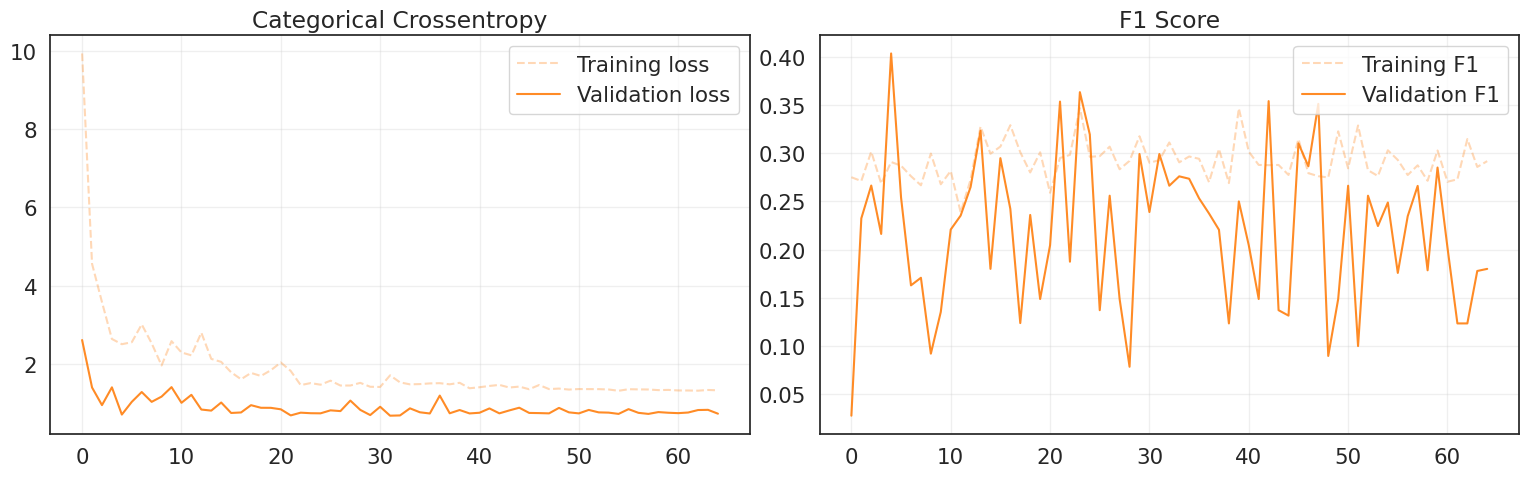

In [29]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(vanilla_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(vanilla_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation F1 score on the second axis
ax2.plot(vanilla_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(vanilla_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

**INFERENCE**

In [35]:
def load_images_from_test_folder(folder):
    images = []
    img_filenames = [] # Initialize img_filenames list

    for filename in os.listdir(folder):

        # Skip masks
        if filename.startswith("mask_"):
            continue

        print(f"Loading {filename}")

        # ---- Load image ----
        img = cv2.imread(os.path.join(folder, filename))
        if img is None:
            continue

        # BGR -> RGB
        img = img[..., ::-1].astype(np.float32) / 255.0

        # ---- Load matching mask ----
        mask_name = "mask_" + filename.split("_")[1]
        mask = cv2.imread(os.path.join(folder, mask_name), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            continue

        # ---- Convert mask to binary ----
        mask = (mask > 0).astype(np.uint8)

        # ---- APPLY ROI MASK ----
        roi = img * mask[..., None]

        # ---- Resize with padding to 224x224 ----
        h, w = roi.shape[:2]
        scale = 224 / max(h, w)
        new_h, new_w = int(h * scale), int(w * scale)
        roi_resized = cv2.resize(roi, (new_w, new_h))

        # Compute padding
        top = (224 - new_h) // 2
        bottom = 224 - new_h - top
        left = (224 - new_w) // 2
        right = 224 - new_w - left

        # Pad with black
        roi_padded = cv2.copyMakeBorder(
            roi_resized, top, bottom, left, right,
            cv2.BORDER_CONSTANT, value=0
        )

        images.append(roi_padded)
        img_filenames.append(filename) # Add filename to list

    return np.array(images), img_filenames # Return images array and filenames list

# Usage
img_path = 'test_data_updated'
test_images, test_image_names = load_images_from_test_folder(img_path) # Unpack correctly
print(f"Loaded {len(test_images)} images")

Loading img_0015.png
Loading img_0042.png
Loading img_0051.png
Loading img_0047.png
Loading img_0017.png
Loading img_0050.png
Loading img_0014.png
Loading img_0060.png
Loading img_0022.png
Loading img_0031.png
Loading img_0028.png
Loading img_0035.png
Loading img_0023.png
Loading img_0059.png
Loading img_0030.png
Loading img_0027.png
Loading img_0029.png
Loading img_0018.png
Loading img_0025.png
Loading img_0037.png
Loading img_0043.png
Loading img_0008.png
Loading img_0012.png
Loading img_0064.png
Loading img_0021.png
Loading img_0013.png
Loading img_0020.png
Loading img_0010.png
Loading img_0052.png
Loading img_0046.png
Loading img_0044.png
Loading img_0049.png
Loading img_0041.png
Loading img_0000.png
Loading img_0053.png
Loading img_0036.png
Loading img_0016.png
Loading img_0034.png
Loading img_0039.png
Loading img_0061.png
Loading img_0032.png
Loading img_0004.png
Loading img_0055.png
Loading img_0009.png
Loading img_0062.png
Loading img_0024.png
Loading img_0011.png
Loading img_0

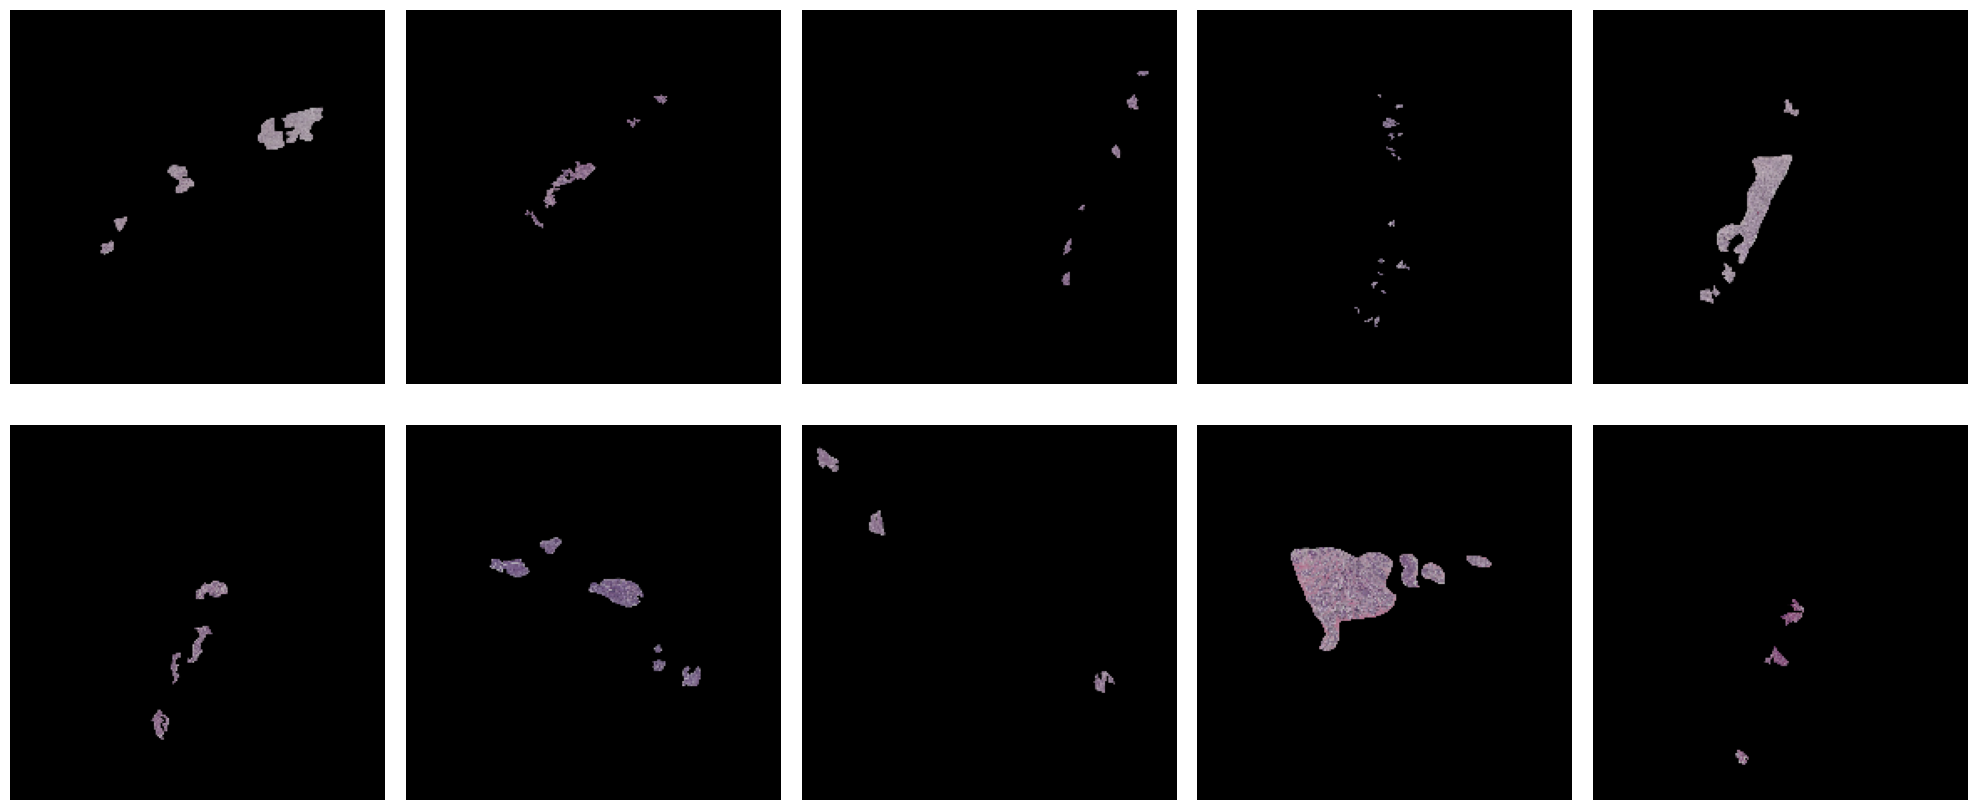

In [36]:
# Number of images to display
num_img = 10
# Create subplots for displaying images
fig, axes = plt.subplots(2, num_img//2, figsize=(20, 9))
for i in range(num_img):
    ax = axes[i%2, i%num_img//2]
    ax.imshow(np.clip(test_images[i], 0, 1)) # Change images[i] to test_images[i]
    ax.axis('off')
plt.tight_layout()
plt.show()

In [39]:
#Create fake labels just for the CustomTensorDataSet to work
labels = np.zeros(len(test_images)) # Use len(test_images) for correct label count
test_dataset = CustomTensorDataset(test_images, labels, transform=val_transform)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [40]:
# Collect predictions and ground truth labels using augmented test loader
test_preds = []
with torch.no_grad():  # Disable gradient computation for inference
    for xb,yb in test_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = best_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        test_preds.append(preds)

# Combine all batches into single arrays
test_preds = np.concatenate(test_preds)
#Change from numerical to back to labels:
label_mapping = {
    'Luminal B': 0,
    'Luminal A': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}
test_preds = [list(label_mapping.keys())[list(label_mapping.values()).index(x)] for x in test_preds]
df = pd.DataFrame({
    "sample_index": test_image_names, # Change names to test_image_names
    "label": test_preds
})

# Sort the DataFrame by 'sample_index'
df = df.sort_values(by='sample_index').reset_index(drop=True)

#output csv file
df.to_csv("submission.csv", index=False)

In [41]:
df

,sample_index,label
0,img_0000.png,Luminal B
1,img_0001.png,Luminal A
2,img_0002.png,Luminal B
3,img_0003.png,Luminal B
4,img_0004.png,Luminal A
...,...,...
472,img_0472.png,Luminal A
473,img_0473.png,Luminal A
474,img_0474.png,Luminal B
475,img_0475.png,Luminal B
